# Eksplorasi Inferensi Stokastik (1000 Sampel $Z^{(\ell)} \sim \mathcal{N}(0, 1)$) & Pita Ketidakpastian
## **Subkasus 1 ($\mathbb{R}^3 \to \mathbb{R}^1$): Variasi 4 (Berdistribusi - Init Beda, ReLU) + Inferensi 1000 Sampel $Z$**

Notebook ini merupakan duplikasi dan pengembangan dari model terbaik pada Bimbingan #10 untuk bobot berdistribusi (**Variasi 4: Inisialisasi Berbeda-beda, Aktivasi ReLU**) dengan tahapan eksplorasi sesuai arahan bimbingan:
1. **Training Model (500 Iterasi)** menggunakan *Reparameterization Trick*:
   $$W^{(\ell)} = M^{(\ell)} + \Sigma^{(\ell)} \odot Z^{(\ell)}, \quad Z^{(\ell)} \sim \mathcal{N}(0, I)$$
2. **Menyimpan Parameter Hasil Training**: Matriks rata-rata $M^{(\ell)*}$, matriks standar deviasi $\Sigma^{(\ell)*}$, dan vektor bias $\mathbf{b}^{(\ell)*}$ untuk setiap layer ($\ell = 1, 2, 3$).
3. **Evaluasi Forward Pass dengan $S = 1000$ Generated $Z^{(\ell)} \sim \mathcal{N}(0, 1)$** untuk setiap layer menggunakan parameter hasil training yang telah disimpan, serta **mengukur waktu komputasinya**.
4. **Perhitungan Persentil** ($P_{2.5}, P_5, P_{25}, P_{50} \text{ (Median)}, P_{75}, P_{95}, P_{97.5}$) serta rata-rata (*mean*) dan standar deviasi dari 1000 hasil prediksi pada setiap sampel data.
5. **Visualisasi Pita Ketidakpastian (*Uncertainty Band*)** berdasarkan persentil hasil 1000 *forward pass*.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

np.set_printoptions(precision=4, suppress=True, linewidth=120)

# 1. Kunci Random Seed (Sama dengan Bimbingan 10)
np.random.seed(67)

# 2. Matriks Data Input X in R^(5 x 3)
X = np.array([
    [0.1, 0.2, 0.3],
    [0.4, 0.1, 0.5],
    [0.2, 0.6, 0.1],
    [0.5, 0.3, 0.2],
    [0.3, 0.4, 0.4]
], dtype=np.float64)
N = X.shape[0]

# 3. Target Pemetaan R^3 -> R^1: y = 0.5*x1 - 0.3*x2 + 0.8*x3
Y = (0.5 * X[:, 0] - 0.3 * X[:, 1] + 0.8 * X[:, 2]).reshape(-1, 1)

# 4. Dimensi Jaringan (Output Layer n3 = 1)
n0, n1, n2, n3 = 3, 4, 6, 1
lr = 0.5
num_epochs = 500

# 5. Fungsi Aktivasi Hidden Layer (ReLU) & Turunannya
def activation(h):
    return np.maximum(0.0, h)

def activation_deriv(h):
    return (h > 0.0).astype(np.float64)

# 6. Inisialisasi Parameter Bobot Berdistribusi (Variasi 4: Berbeda-beda)
M1 = np.array([
    [ 0.1, -0.2,  0.3,  0.1],
    [-0.1,  0.3, -0.1,  0.2],
    [ 0.2,  0.1, -0.2, -0.3]
], dtype=np.float64)
Sigma1 = np.array([
    [0.1, 0.2, 0.1, 0.2],
    [0.2, 0.1, 0.2, 0.1],
    [0.1, 0.2, 0.1, 0.2]
], dtype=np.float64)
b1 = np.array([[0.1, -0.1, 0.2, 0.0]], dtype=np.float64)

M2 = np.array([
    [ 0.2, -0.1,  0.3,  0.1, -0.2,  0.1],
    [-0.2,  0.2, -0.1,  0.3,  0.1, -0.1],
    [ 0.1, -0.3,  0.2, -0.1,  0.2,  0.3],
    [-0.1,  0.1, -0.2,  0.2, -0.1,  0.2]
], dtype=np.float64)
Sigma2 = np.array([
    [0.1, 0.2, 0.1, 0.2, 0.1, 0.2],
    [0.2, 0.1, 0.2, 0.1, 0.2, 0.1],
    [0.1, 0.2, 0.1, 0.2, 0.1, 0.2],
    [0.2, 0.1, 0.2, 0.1, 0.2, 0.1]
], dtype=np.float64)
b2 = np.array([[0.1, 0.0, -0.1, 0.2, -0.2, 0.1]], dtype=np.float64)

M3 = np.array([
    [ 0.3],
    [-0.2],
    [ 0.4],
    [-0.1],
    [ 0.2],
    [-0.3]
], dtype=np.float64)
Sigma3 = np.array([[0.1], [0.2], [0.1], [0.2], [0.1], [0.2]], dtype=np.float64)
b3 = np.array([[0.1]], dtype=np.float64)

print("Data Input X (5 x 3):\n", X)
print(f"\nData Target Y (5 x {n3}):\n", Y)


Data Input X (5 x 3):
 [[0.1 0.2 0.3]
 [0.4 0.1 0.5]
 [0.2 0.6 0.1]
 [0.5 0.3 0.2]
 [0.3 0.4 0.4]]

Data Target Y (5 x 1):
 [[0.23]
 [0.57]
 [0.  ]
 [0.32]
 [0.35]]


In [2]:
# =========================================================================
# TAHAP 1: PELATIHAN MODEL (500 ITERASI) & RECORD PARAMETER HASIL TRAINING
# =========================================================================
history = []
milestones = [1, 2, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
predictions_history = {}

t_train_start = time.perf_counter()

for epoch in range(1, num_epochs + 1):
    # --- REPARAMETERIZATION TRICK & FORWARD PASS ---
    Z1 = np.random.randn(n0, n1)
    W1 = M1 + Sigma1 * Z1
    H1 = X @ W1 + b1
    X1 = activation(H1)
    
    Z2 = np.random.randn(n1, n2)
    W2 = M2 + Sigma2 * Z2
    H2 = X1 @ W2 + b2
    X2 = activation(H2)
    
    Z3 = np.random.randn(n2, n3)
    W3 = M3 + Sigma3 * Z3
    H3 = X2 @ W3 + b3
    Y_hat = H3
    
    # Evaluasi Loss MSE
    loss = (0.5 / N) * np.sum((Y - Y_hat) ** 2)
    history.append((epoch, loss, Y_hat.copy()))
    if epoch in milestones:
        predictions_history[epoch] = Y_hat.copy()
        
    # --- BACKWARD PASS ---
    dL_dH3 = (1.0 / N) * (Y_hat - Y)
    dL_dW3 = X2.T @ dL_dH3
    dL_db3 = np.ones((1, N)) @ dL_dH3
    dL_dM3 = dL_dW3
    dL_dSigma3 = dL_dW3 * Z3
    
    dL_dX2 = dL_dH3 @ W3.T
    dL_dH2 = dL_dX2 * activation_deriv(H2)
    dL_dW2 = X1.T @ dL_dH2
    dL_db2 = np.ones((1, N)) @ dL_dH2
    dL_dM2 = dL_dW2
    dL_dSigma2 = dL_dW2 * Z2
    
    dL_dX1 = dL_dH2 @ W2.T
    dL_dH1 = dL_dX1 * activation_deriv(H1)
    dL_dW1 = X.T @ dL_dH1
    dL_db1 = np.ones((1, N)) @ dL_dH1
    dL_dM1 = dL_dW1
    dL_dSigma1 = dL_dW1 * Z1
    
    # --- UPDATE PARAMETER DISTRIBUSI & BIAS ---
    M3 -= lr * dL_dM3
    Sigma3 -= lr * dL_dSigma3
    b3 -= lr * dL_db3
    
    M2 -= lr * dL_dM2
    Sigma2 -= lr * dL_dSigma2
    b2 -= lr * dL_db2
    
    M1 -= lr * dL_dM1
    Sigma1 -= lr * dL_dSigma1
    b1 -= lr * dL_db1

t_train_end = time.perf_counter()
train_duration_ms = (t_train_end - t_train_start) * 1000.0

# Simpan (Record) Parameter Hasil Training Setelah 500 Iterasi
trained_params = {
    "M1": M1.copy(), "Sigma1": Sigma1.copy(), "b1": b1.copy(),
    "M2": M2.copy(), "Sigma2": Sigma2.copy(), "b2": b2.copy(),
    "M3": M3.copy(), "Sigma3": Sigma3.copy(), "b3": b3.copy()
}
np.savez("trained_params_v4_r3_r" + str(n3) + ".npz", **trained_params)

print(f"Pelatihan 500 iterasi selesai dalam waktu: {train_duration_ms:.4f} ms ({train_duration_ms/1000:.6f} detik)")
print(f"MSE Loss Akhir (Iterasi 500): {history[-1][1]:.6f}\n")

print("================ PARAMETER HASIL TRAINING (ITERASI 500) ================")
for ell in [1, 2, 3]:
    print(f"--- LAYER {ell} ---")
    print(f"M^({ell})* :\n{trained_params[f'M{ell}']}")
    print(f"Sigma^({ell})* :\n{trained_params[f'Sigma{ell}']}")
    print(f"b^({ell})* :\n{trained_params[f'b{ell}']}\n")


Pelatihan 500 iterasi selesai dalam waktu: 83.9699 ms (0.083970 detik)
MSE Loss Akhir (Iterasi 500): 0.000133

================ PARAMETER HASIL TRAINING (ITERASI 500) ================
--- LAYER 1 ---
M^(1)* :
[[ 0.4538 -0.3547  0.3654 -0.0875]
 [-0.2773  0.3559 -0.2453  0.3257]
 [ 0.6432 -0.0575 -0.0857 -0.5073]]
Sigma^(1)* :
[[-0.0053  0.0612  0.0121 -0.0036]
 [-0.0004  0.0114  0.073  -0.0015]
 [-0.0063  0.0673  0.0233 -0.015 ]]
b^(1)* :
[[ 0.0123 -0.0503  0.0208  0.2268]]

--- LAYER 2 ---
M^(2)* :
[[ 0.4972 -0.2148  0.6704 -0.0031 -0.2    -0.0742]
 [-0.2706  0.2426 -0.1517  0.3181  0.1    -0.0536]
 [ 0.1264 -0.2923  0.2496 -0.1356  0.2     0.2586]
 [-0.2795  0.1866 -0.3613  0.2308 -0.1     0.2906]]
Sigma^(2)* :
[[-0.0072  0.0462  0.012   0.1617  0.1     0.1024]
 [ 0.125   0.0696  0.1172  0.091   0.2     0.0917]
 [ 0.0605  0.1648  0.018   0.1802  0.1     0.1461]
 [ 0.0419  0.0314  0.0381  0.0905  0.2     0.0531]]
b^(2)* :
[[ 0.0882  0.1053  0.085   0.0335 -0.2    -0.0026]]

--- LAYER 

In [3]:
# =========================================================================
# TAHAP 2: FORWARD PASS DENGAN 1000 GENERATED Z ~ N(0, 1) SETIAP LAYER
# =========================================================================
num_mc_samples = 1000

# Ambil parameter hasil training yang telah disimpan
M1_opt, Sigma1_opt, b1_opt = trained_params["M1"], trained_params["Sigma1"], trained_params["b1"]
M2_opt, Sigma2_opt, b2_opt = trained_params["M2"], trained_params["Sigma2"], trained_params["b2"]
M3_opt, Sigma3_opt, b3_opt = trained_params["M3"], trained_params["Sigma3"], trained_params["b3"]

# Kunci seed khusus untuk pengujian inferensi Monte Carlo agar reproducible
np.random.seed(1000)

# --- Cara 1: Looping Sekuensial 1000 Kali Forward Pass ---
Y_hat_samples_loop = np.zeros((num_mc_samples, N, n3), dtype=np.float64)
Z1_records = np.zeros((num_mc_samples, n0, n1), dtype=np.float64)
Z2_records = np.zeros((num_mc_samples, n1, n2), dtype=np.float64)
Z3_records = np.zeros((num_mc_samples, n2, n3), dtype=np.float64)

t_mc_loop_start = time.perf_counter()
for s in range(num_mc_samples):
    # Generate Z^(l) ~ N(0, 1) untuk setiap layer
    Z1_s = np.random.randn(n0, n1)
    Z2_s = np.random.randn(n1, n2)
    Z3_s = np.random.randn(n2, n3)
    
    Z1_records[s] = Z1_s
    Z2_records[s] = Z2_s
    Z3_records[s] = Z3_s
    
    # Forward Pass Layer 1
    W1_s = M1_opt + Sigma1_opt * Z1_s
    H1_s = X @ W1_s + b1_opt
    X1_s = activation(H1_s)
    
    # Forward Pass Layer 2
    W2_s = M2_opt + Sigma2_opt * Z2_s
    H2_s = X1_s @ W2_s + b2_opt
    X2_s = activation(H2_s)
    
    # Forward Pass Layer 3 (Output)
    W3_s = M3_opt + Sigma3_opt * Z3_s
    H3_s = X2_s @ W3_s + b3_opt
    Y_hat_samples_loop[s] = H3_s

t_mc_loop_end = time.perf_counter()
mc_loop_duration_ms = (t_mc_loop_end - t_mc_loop_start) * 1000.0

# --- Cara 2: Vectorized / Batch Tensor 3D (1000 sampel sekaligus) ---
np.random.seed(1000)
t_mc_vec_start = time.perf_counter()

Z1_batch = np.random.randn(num_mc_samples, n0, n1)
Z2_batch = np.random.randn(num_mc_samples, n1, n2)
Z3_batch = np.random.randn(num_mc_samples, n2, n3)

W1_batch = M1_opt[None, :, :] + Sigma1_opt[None, :, :] * Z1_batch          # (1000, n0, n1)
H1_batch = np.matmul(X[None, :, :], W1_batch) + b1_opt[None, :, :]         # (1000, N, n1)
X1_batch = activation(H1_batch)

W2_batch = M2_opt[None, :, :] + Sigma2_opt[None, :, :] * Z2_batch          # (1000, n1, n2)
H2_batch = np.matmul(X1_batch, W2_batch) + b2_opt[None, :, :]              # (1000, N, n2)
X2_batch = activation(H2_batch)

W3_batch = M3_opt[None, :, :] + Sigma3_opt[None, :, :] * Z3_batch          # (1000, n2, n3)
Y_hat_samples_vec = np.matmul(X2_batch, W3_batch) + b3_opt[None, :, :]     # (1000, N, n3)

t_mc_vec_end = time.perf_counter()
mc_vec_duration_ms = (t_mc_vec_end - t_mc_vec_start) * 1000.0

# Gunakan hasil Y_hat_samples_loop untuk analisis persentil
Y_hat_mc = Y_hat_samples_loop

print("================ RINGKASAN WAKTU KOMPUTASI ================")
print(f"1. Waktu Training (500 Iterasi)                   : {train_duration_ms:.4f} ms ({train_duration_ms/1000:.6f} s)")
print(f"2. Waktu Forward Pass 1000 Sampel Z (Looping)     : {mc_loop_duration_ms:.4f} ms ({mc_loop_duration_ms/1000:.6f} s) -> Rata-rata {mc_loop_duration_ms/1000:.4f} ms / pass")
print(f"3. Waktu Forward Pass 1000 Sampel Z (Vectorized)  : {mc_vec_duration_ms:.4f} ms ({mc_vec_duration_ms/1000:.6f} s)")
print(f"4. Shape Tensor Prediksi Hasil 1000 Forward Pass  : {Y_hat_mc.shape} (1000 sampel x {N} data x {n3} output)")


================ RINGKASAN WAKTU KOMPUTASI ================
1. Waktu Training (500 Iterasi)                   : 83.9699 ms (0.083970 s)
2. Waktu Forward Pass 1000 Sampel Z (Looping)     : 51.2488 ms (0.051249 s) -> Rata-rata 0.0512 ms / pass
3. Waktu Forward Pass 1000 Sampel Z (Vectorized)  : 8.8074 ms (0.008807 s)
4. Shape Tensor Prediksi Hasil 1000 Forward Pass  : (1000, 5, 1) (1000 sampel x 5 data x 1 output)


In [4]:
# =========================================================================
# TAHAP 3: PERHITUNGAN PERSENTIL, RATA-RATA, & STANDAR DEVIASI PREDIKSI
# =========================================================================
t_stat_start = time.perf_counter()

percentiles_list = [2.5, 5.0, 25.0, 50.0, 75.0, 95.0, 97.5]
perc_values = np.percentile(Y_hat_mc, q=percentiles_list, axis=0)  # shape: (7, N, n3)
mean_pred = np.mean(Y_hat_mc, axis=0)                              # shape: (N, n3)
std_pred = np.std(Y_hat_mc, axis=0, ddof=1)                        # shape: (N, n3)

t_stat_end = time.perf_counter()
stat_duration_ms = (t_stat_end - t_stat_start) * 1000.0
print(f"Waktu perhitungan statistik & persentil: {stat_duration_ms:.4f} ms\n")

for out_idx in range(n3):
    out_label = f"Output y_{out_idx+1}" if n3 > 1 else "Output y"
    print(f"================ TABEL PERSENTIL & STATISTIK PREDIKSI ({out_label}) ================")
    df_perc = pd.DataFrame({
        "Sampel (i)": [f"Data ke-{i+1}" for i in range(N)],
        "Target Asli": Y[:, out_idx],
        "Mean Prediksi": mean_pred[:, out_idx],
        "Std Dev (s)": std_pred[:, out_idx],
        "P2.5 (Batas Bawah 95%)": perc_values[0, :, out_idx],
        "P5 (Batas Bawah 90%)": perc_values[1, :, out_idx],
        "P25 (Q1)": perc_values[2, :, out_idx],
        "P50 (Median)": perc_values[3, :, out_idx],
        "P75 (Q3)": perc_values[4, :, out_idx],
        "P95 (Batas Atas 90%)": perc_values[5, :, out_idx],
        "P97.5 (Batas Atas 95%)": perc_values[6, :, out_idx],
        "Lebar Pita 95% (P97.5 - P2.5)": perc_values[6, :, out_idx] - perc_values[0, :, out_idx]
    })
    print(df_perc.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print()
    
    # Evaluasi MSE dari Rata-rata (Mean) dan Median (P50) terhadap Target Asli
    mse_mean = (0.5 / N) * np.sum((Y[:, out_idx] - mean_pred[:, out_idx]) ** 2)
    mse_median = (0.5 / N) * np.sum((Y[:, out_idx] - perc_values[3, :, out_idx]) ** 2)
    print(f"[{out_label}] MSE menggunakan Mean 1000 sampel   : {mse_mean:.6f}")
    print(f"[{out_label}] MSE menggunakan Median 1000 sampel : {mse_median:.6f}\n")


Waktu perhitungan statistik & persentil: 1.6886 ms

================ TABEL PERSENTIL & STATISTIK PREDIKSI (Output y) ================
Sampel (i)  Target Asli  Mean Prediksi  Std Dev (s)  P2.5 (Batas Bawah 95%)  P5 (Batas Bawah 90%)  P25 (Q1)  P50 (Median)  P75 (Q3)  P95 (Batas Atas 90%)  P97.5 (Batas Atas 95%)  Lebar Pita 95% (P97.5 - P2.5)
 Data ke-1       0.2300         0.2519       0.0083                  0.2361                0.2387    0.2463        0.2520    0.2574                0.2652                  0.2673                         0.0312
 Data ke-2       0.5700         0.5724       0.0108                  0.5479                0.5521    0.5662        0.5731    0.5797                0.5879                  0.5906                         0.0427
 Data ke-3       0.0000         0.0019       0.0072                 -0.0134               -0.0098   -0.0028        0.0019    0.0068                0.0135                  0.0159                         0.0292
 Data ke-4       0.3200       

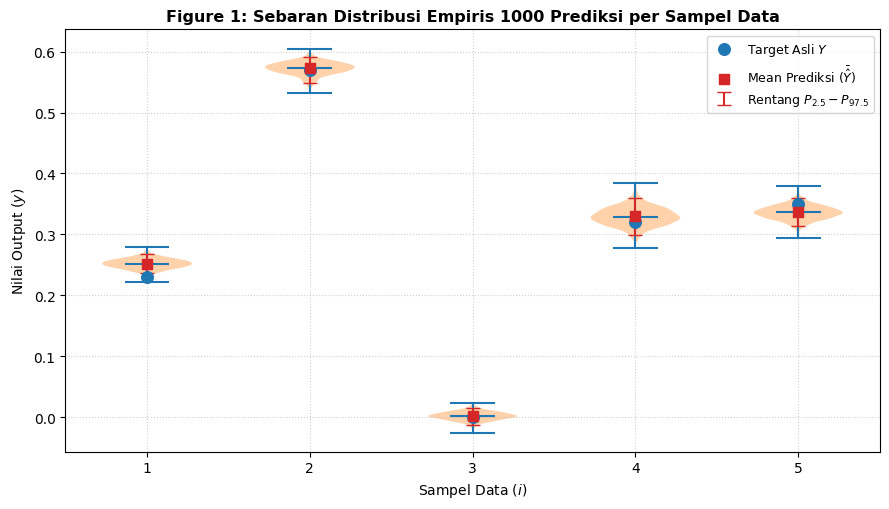

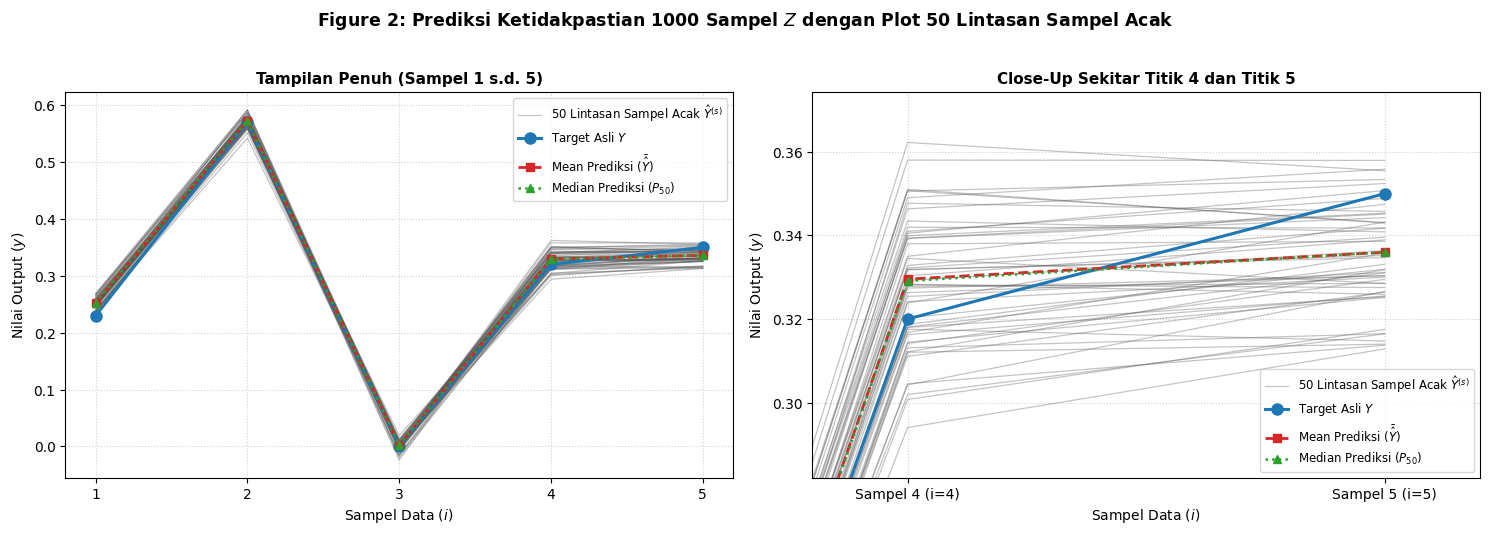

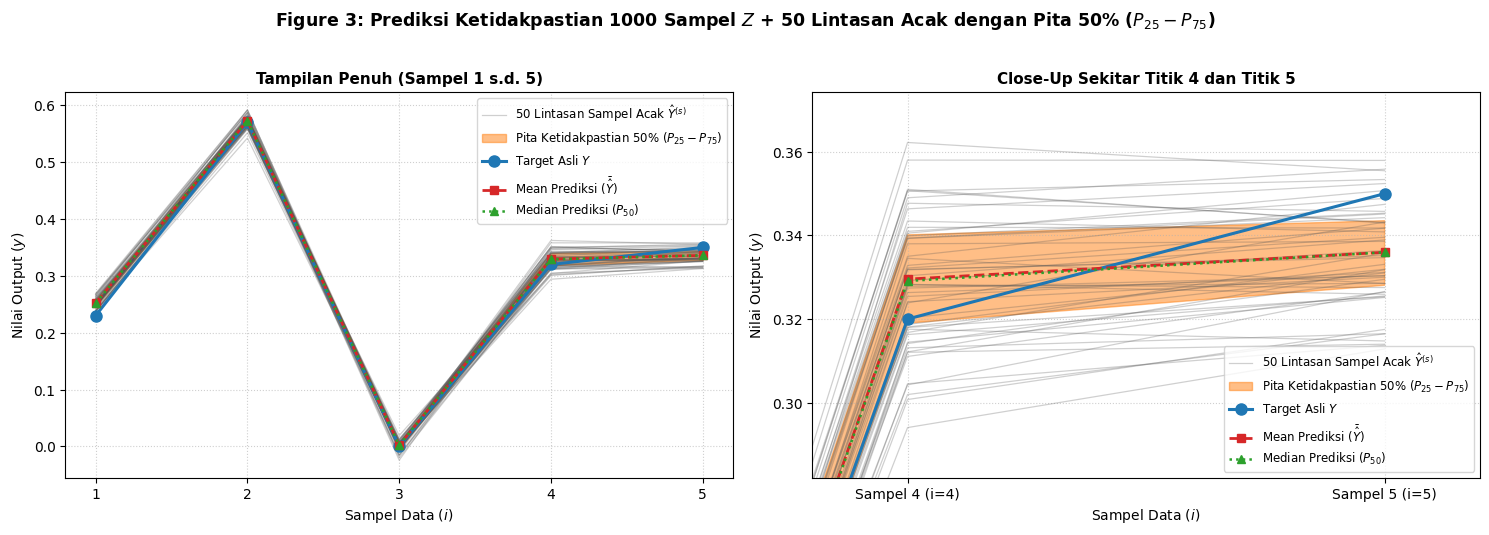

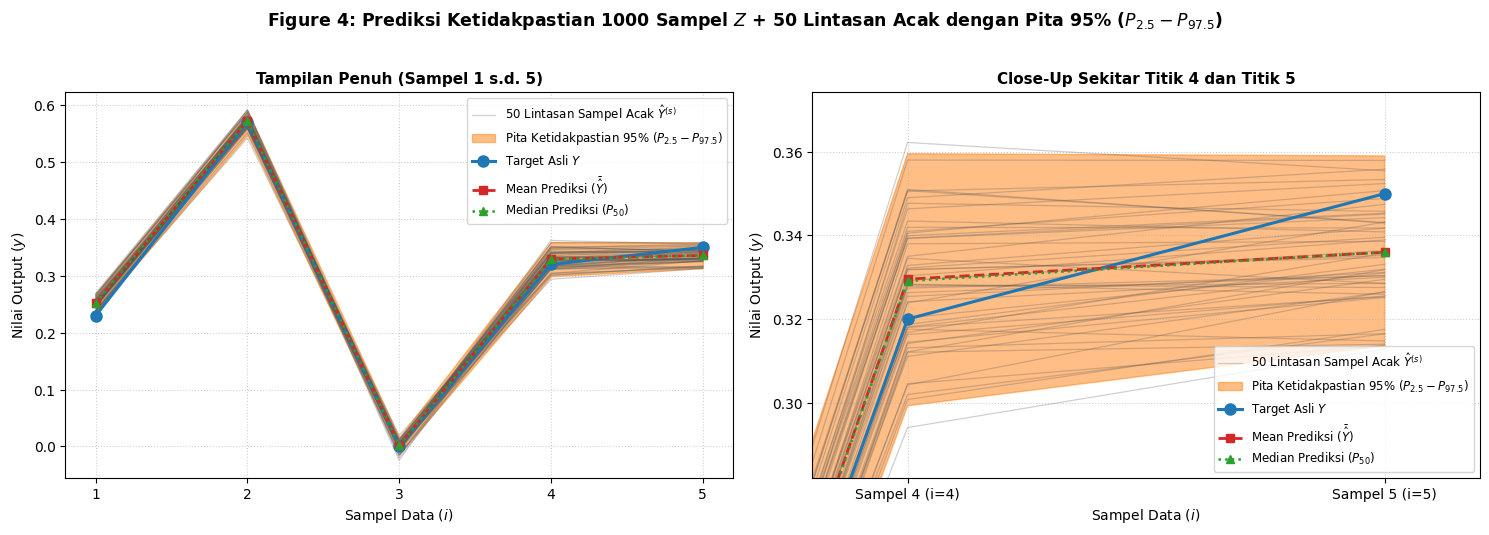

In [62]:
# =========================================================================
# TAHAP 4: VISUALISASI 4 FIGURE PITA KETIDAKPASTIAN (UNCERTAINTY BAND) R^3 -> R^1
# =========================================================================
samples = np.arange(1, N + 1)

# Hitung batas y untuk close-up sekitar titik 4 dan titik 5 (index 3 dan 4)
y_zoom_min = min(np.min(Y_hat_mc[:50, 3:5, 0]), np.min(perc_values[0, 3:5, 0]), np.min(Y[3:5, 0])) - 0.012
y_zoom_max = max(np.max(Y_hat_mc[:50, 3:5, 0]), np.max(perc_values[6, 3:5, 0]), np.max(Y[3:5, 0])) + 0.012

# =========================================================================
# FIGURE 1: Sebaran Distribusi Empiris 1000 Prediksi per Sampel Data (1 Plot)
# =========================================================================
fig1, ax1 = plt.subplots(figsize=(9, 5.2))
parts = ax1.violinplot([Y_hat_mc[:, i, 0] for i in range(N)], positions=samples,
                       showmeans=False, showmedians=True, widths=0.55)
for pc in parts['bodies']:
    pc.set_facecolor('#ff7f0e')
    pc.set_alpha(0.35)

ax1.scatter(samples, Y[:, 0], color='#1f77b4', s=70, zorder=5, label='Target Asli $Y$')
ax1.scatter(samples, mean_pred[:, 0], color='#d62728', marker='s', s=55, zorder=5, label=r'Mean Prediksi ($\bar{\hat{Y}}$)')
ax1.errorbar(samples, mean_pred[:, 0],
             yerr=[mean_pred[:, 0] - perc_values[0, :, 0], perc_values[6, :, 0] - mean_pred[:, 0]],
             fmt='none', ecolor='#d62728', elinewidth=1.5, capsize=5, label=r'Rentang $P_{2.5} - P_{97.5}$')

ax1.set_title('Figure 1: Sebaran Distribusi Empiris 1000 Prediksi per Sampel Data', fontsize=11.5, fontweight='bold')
ax1.set_xlabel('Sampel Data ($i$)', fontsize=10)
ax1.set_ylabel('Nilai Output ($y$)', fontsize=10)
ax1.set_xticks(samples)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(fontsize=9, loc='best')
plt.tight_layout()
plt.show()

# Fungsi pembantu untuk membuat Figure 2, 3, dan 4 (Kiri: Full, Kanan: Close-Up Titik 4 & 5)
def plot_full_and_closeup_r1(fig_num, title_suffix, band_type=None):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
    
    for idx, is_zoom in enumerate([False, True]):
        ax = axes[idx]
        for s in range(50):
            ax.plot(samples, Y_hat_mc[s, :, 0], color='#555555', alpha=0.35 if not band_type else 0.28,
                    linewidth=0.9, label=r'50 Lintasan Sampel Acak $\hat{Y}^{(s)}$' if s == 0 else "")
            
        if band_type == '50':
            ax.fill_between(samples, perc_values[2, :, 0], perc_values[4, :, 0],
                            color='#ff7f0e', alpha=0.50, label=r'Pita Ketidakpastian 50% ($P_{25} - P_{75}$)')
        elif band_type == '95':
            ax.fill_between(samples, perc_values[0, :, 0], perc_values[6, :, 0],
                            color='#ff7f0e', alpha=0.50, label=r'Pita Ketidakpastian 95% ($P_{2.5} - P_{97.5}$)')
            
        ax.plot(samples, Y[:, 0], 'o-', color='#1f77b4', linewidth=2.2, markersize=8, zorder=5, label='Target Asli $Y$')
        ax.plot(samples, mean_pred[:, 0], 's--', color='#d62728', linewidth=2.0, markersize=6, zorder=5, label=r'Mean Prediksi ($\bar{\hat{Y}}$)')
        ax.plot(samples, perc_values[3, :, 0], '^:', color='#2ca02c', linewidth=1.8, markersize=6, zorder=5, label=r'Median Prediksi ($P_{50}$)')
        
        if not is_zoom:
            ax.set_xticks(samples)
            ax.set_title(f'Tampilan Penuh (Sampel 1 s.d. 5)', fontsize=11, fontweight='bold')
        else:
            ax.set_xlim(3.8, 5.2)
            ax.set_ylim(y_zoom_min, y_zoom_max)
            ax.set_xticks([4, 5])
            ax.set_xticklabels(['Sampel 4 (i=4)', 'Sampel 5 (i=5)'])
            ax.set_title(f'Close-Up Sekitar Titik 4 dan Titik 5', fontsize=11, fontweight='bold')
            
        ax.set_xlabel('Sampel Data ($i$)', fontsize=10)
        ax.set_ylabel('Nilai Output ($y$)', fontsize=10)
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(fontsize=8.5, loc='best')
        
    fig.suptitle(f'Figure {fig_num}: {title_suffix}', fontsize=12.5, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# =========================================================================
# FIGURE 2: Plot 50 Lintasan Sampel Acak (Full vs Close-Up Titik 4 & 5)
# =========================================================================
plot_full_and_closeup_r1(2, 'Prediksi Ketidakpastian 1000 Sampel $Z$ dengan Plot 50 Lintasan Sampel Acak', band_type=None)

# =========================================================================
# FIGURE 3: Plot 50 Lintasan Sampel Acak + Pita 50% (Full vs Close-Up Titik 4 & 5)
# =========================================================================
plot_full_and_closeup_r1(3, 'Prediksi Ketidakpastian 1000 Sampel $Z$ + 50 Lintasan Acak dengan Pita 50% ($P_{25} - P_{75}$)', band_type='50')

# =========================================================================
# FIGURE 4: Plot 50 Lintasan Sampel Acak + Pita 95% (Full vs Close-Up Titik 4 & 5)
# =========================================================================
plot_full_and_closeup_r1(4, 'Prediksi Ketidakpastian 1000 Sampel $Z$ + 50 Lintasan Acak dengan Pita 95% ($P_{2.5} - P_{97.5}$)', band_type='95')


---
### **Visualisasi Geometris Tensor 3D (Balok): Indexing `[None, :, :]` dan *Broadcasting* 1000 Sampel**

Ketika kita mengubah matriks 2D `M1_opt` berukuran `(3, 4)` menjadi `M1_opt[None, :, :]` berukuran `(1, 3, 4)` lalu mengoperasikannya dengan `Z1_batch` yang berukuran `(1000, 3, 4)`:
1. **`M1_opt[None, :, :]` dengan shape `(1, 3, 4)`**: Berbentuk **balok tipis 1 lapis** (1 sampel $\times$ 3 baris $\times$ 4 kolom) yang berisi nilai parameter rata-rata $M^{(1)*}$ hasil training.
2. **`Z1_batch[:5]` dengan shape `(5, 3, 4)`** *(diambil 5 lapis pertama dari 1000 lapis agar balok terlihat jelas)*: Berbentuk **balok 5 lapis** di mana setiap lapis ke-$s$ berisi matriks acak $Z_1^{(s)} \sim \mathcal{N}(0, 1)$ yang berbeda-beda.
3. **Hasil *Broadcasting* `W1_batch[:5]` dengan shape `(5, 3, 4)`**: NumPy otomatis menggandakan (*broadcast*) balok tipis 1 lapis `M1_opt` dan `Sigma1_opt` ke seluruh 1000 lapis `Z1_batch` sehingga menghasilkan balok bobot $W_1^{(s)} = M^{(1)*} + \Sigma^{(1)*} \odot Z_1^{(s)}$.


C:\Users\MyBook Z Series\AppData\Local\Temp\ipykernel_17444\2428885134.py:81: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


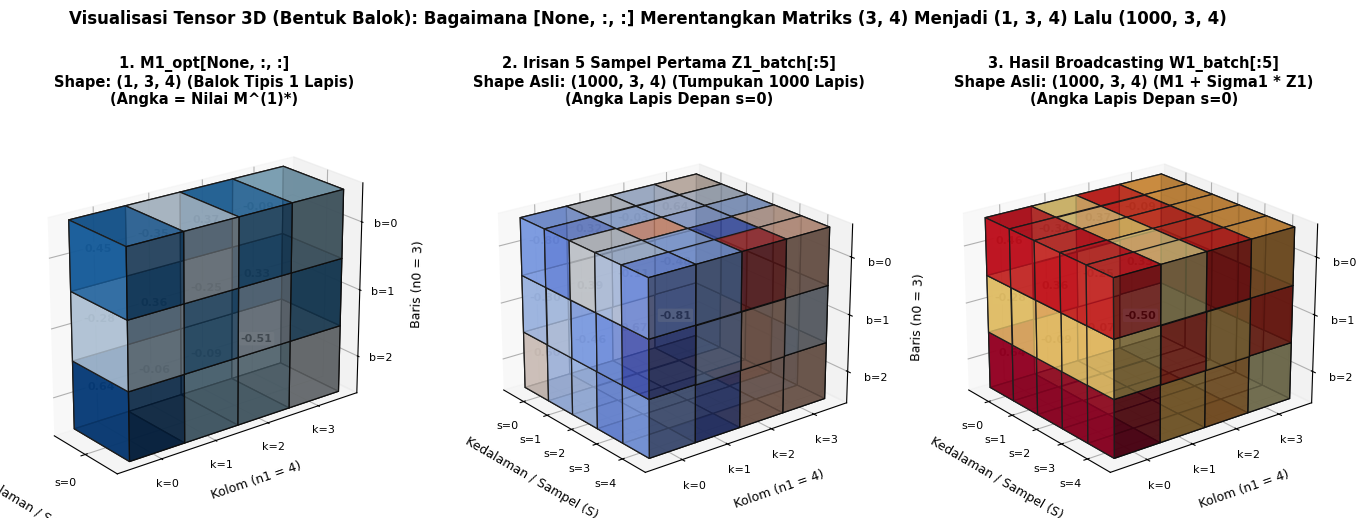

In [6]:
# =========================================================================
# TAHAP 5: VISUALISASI BALOK 3D (TENSOR 3D & BROADCASTING [None, :, :])
# =========================================================================
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Kita visualisasikan 5 lapis pertama dari 1000 sampel (S_vis = 5) agar tiap sel balok dan angkanya terbaca jelas
S_vis = 5
M1_3d = M1_opt[None, :, :]          # Shape: (1, 3, 4) -> Balok tipis 1 lapis
Z1_3d_sub = Z1_batch[:S_vis, :, :]  # Shape: (5, 3, 4) -> 5 lapis pertama dari (1000, 3, 4)
W1_3d_sub = W1_batch[:S_vis, :, :]  # Shape: (5, 3, 4) -> Hasil broadcasting M1 + Sigma1 * Z1

def draw_tensor_block(ax, tensor, title, cmap_name='coolwarm', show_text=True):
    S_dim, R_dim, C_dim = tensor.shape
    filled = np.ones((S_dim, C_dim, R_dim), dtype=bool)
    
    norm = mcolors.Normalize(vmin=np.min(tensor) - 0.1, vmax=np.max(tensor) + 0.1)
    cmap = plt.get_cmap(cmap_name)
    
    facecolors = np.empty(filled.shape + (4,), dtype=float)
    for s in range(S_dim):
        for r in range(R_dim):
            for c in range(C_dim):
                # Balik indeks baris agar baris ke-0 berada di paling atas balok
                r_plot = (R_dim - 1) - r
                rgba = list(cmap(norm(tensor[s, r, c])))
                rgba[3] = 0.82  # Transparansi
                facecolors[s, c, r_plot] = rgba

    ax.voxels(filled, facecolors=facecolors, edgecolors='#222222', linewidth=0.9)
    
    # Tuliskan nilai angka pada lapisan paling depan (s = 0)
    if show_text:
        for r in range(R_dim):
            for c in range(C_dim):
                r_plot = (R_dim - 1) - r
                val = tensor[0, r, c]
                ax.text(0.0, c + 0.5, r_plot + 0.5, f"{val:.2f}",
                        color='black', fontweight='bold', fontsize=8,
                        ha='center', va='center',
                        bbox=dict(boxstyle='round,pad=0.15', facecolor='white', alpha=0.8, edgecolor='none'))

    ax.set_title(title, fontsize=10.5, fontweight='bold', pad=12)
    ax.set_xlabel('\nKedalaman / Sampel (S)', fontsize=9)
    ax.set_ylabel('\nKolom (n1 = 4)', fontsize=9)
    ax.set_zlabel('\nBaris (n0 = 3)', fontsize=9)
    
    ax.set_xticks(np.arange(S_dim) + 0.5)
    ax.set_xticklabels([f"s={i}" for i in range(S_dim)], fontsize=8)
    ax.set_yticks(np.arange(C_dim) + 0.5)
    ax.set_yticklabels([f"k={j}" for j in range(C_dim)], fontsize=8)
    ax.set_zticks(np.arange(R_dim) + 0.5)
    ax.set_zticklabels([f"b={R_dim-1-i}" for i in range(R_dim)], fontsize=8)
    
    # Atur rasio proporsi balok dan sudut pandang kamera 3D
    ax.set_box_aspect((max(S_dim * 0.75, 1.4), C_dim, R_dim))
    ax.view_init(elev=22, azim=-38)

fig = plt.figure(figsize=(17, 5.8))

# Panel 1: M1_opt[None, :, :] berukuran (1, 3, 4)
ax1 = fig.add_subplot(1, 3, 1, projection='3d')
draw_tensor_block(ax1, M1_3d,
                  f"1. M1_opt[None, :, :]\nShape: {M1_3d.shape} (Balok Tipis 1 Lapis)\n(Angka = Nilai M^(1)*)",
                  cmap_name='Blues', show_text=True)

# Panel 2: Z1_batch[:5] berukuran (5, 3, 4) mewakili (1000, 3, 4)
ax2 = fig.add_subplot(1, 3, 2, projection='3d')
draw_tensor_block(ax2, Z1_3d_sub,
                  f"2. Irisan 5 Sampel Pertama Z1_batch[:5]\nShape Asli: {Z1_batch.shape} (Tumpukan 1000 Lapis)\n(Angka Lapis Depan s=0)",
                  cmap_name='coolwarm', show_text=True)

# Panel 3: W1_batch[:5] berukuran (5, 3, 4) hasil Broadcasting
ax3 = fig.add_subplot(1, 3, 3, projection='3d')
draw_tensor_block(ax3, W1_3d_sub,
                  f"3. Hasil Broadcasting W1_batch[:5]\nShape Asli: {W1_batch.shape} (M1 + Sigma1 * Z1)\n(Angka Lapis Depan s=0)",
                  cmap_name='YlOrRd', show_text=True)

plt.suptitle("Visualisasi Tensor 3D (Bentuk Balok): Bagaimana [None, :, :] Merentangkan Matriks (3, 4) Menjadi (1, 3, 4) Lalu (1000, 3, 4)",
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
